In [1]:
using LinearAlgebra
using DifferentialEquations, Plots
using BenchmarkTools
using HypothesisTests
default(grid=false,legend=false, size=(400,320), dpi=300, tickfontsize=16, lw=2, lc=:gray, labelfontsize=16, tickdir=:out, fontfamily="Arial", legendfontsize=13, markercolor=:indianred)


mydir = "../helper/"
include(mydir * "base.jl")
include(mydir * "optimization.jl")
include(mydir * "misc.jl")

annotate_exp_traj (generic function with 2 methods)

### xy01

In [2]:
using DelimitedFiles
# INSERT YOUR OWN DATA DIRECTORY AND FILENAME HERE
# E. coli MG1655 (CGSC 6300)/20090131/xy01c1/ch1_cell0.dat
data_dir = "/Users/shijiezhang/Dropbox (MIT)/stochastic_learning/complete data Curr Biol 20, 1099-1103 (2010)/E. coli MG1655 (CGSC 6300)/20090129/xy01/"
filename_all = readdir(data_dir);
DT = 0.01;
DL = 0.05;

In [3]:
select_filename = Vector{String}(undef, 11)
select_filename[1] = "ch0_cell0.dat"
select_filename[2] = "ch1_cell0.dat"
select_filename[3] = "ch2_cell0.dat"
select_filename[4] = "ch3_cell0.dat"
select_filename[5] = "ch4_cell0.dat"
select_filename[6] = "ch5_cell0.dat"
select_filename[7] = "ch6_cell0.dat"
select_filename[8] = "ch7_cell0.dat"
select_filename[9] = "ch8_cell0.dat"
select_filename[10] = "ch9_cell0.dat"
select_filename[11] = "ch10_cell0.dat"


"ch10_cell0.dat"

In [4]:

select_time_all = Vector{Vector{Tuple{Float64, Float64}}}(undef, length(select_filename))
select_time_all[1] = [(0, 11.41), (12.31, 15.97)]
select_time_all[2] = [(0, 21.99)] 
select_time_all[3] = [(0, 15.35)] 
select_time_all[4] = [(0., 15.88), (16.32, 20.12)]
select_time_all[5] = [(0, 27.31)] 
select_time_all[6] = [(0, 27.31)] 
select_time_all[7] = [(0, 23.55)]
select_time_all[8] = [(0, 27.31)] 
select_time_all[9] = [(0, 17.96), (18.64, 24.04)] 
select_time_all[10] = [(0, 22.71)]
select_time_all[11] = [(25.78, 27.31)] 

# annotate
Lobs_ = []
tobs_ = []



Any[]

In [5]:
for idx in eachindex(select_filename)
    tab = readdlm(data_dir * select_filename[idx]);
    varnames = convert(Vector{String}, tab[1,:]);
    tobs = tab[2:end,findfirst(varnames .== "time")] * DT;
    Lobs = tab[2:end,findfirst(varnames .== "length")] * DL;
    Lobs_idx, tobs_idx = filter_exp_traj(Lobs, tobs; select_time = select_time_all[idx]);
    Lobs_ = vcat(Lobs_, Lobs_idx)
    tobs_ = vcat(tobs_, tobs_idx)
end
Lobs_ = convert.(Vector{Float64}, Lobs_);
tobs_ = convert.(Vector{Float64}, tobs_);

In [6]:
isdiv_, dtobs_ = annotate_exp_traj(Lobs_, tobs_);
sum(vcat(isdiv_...))

1043

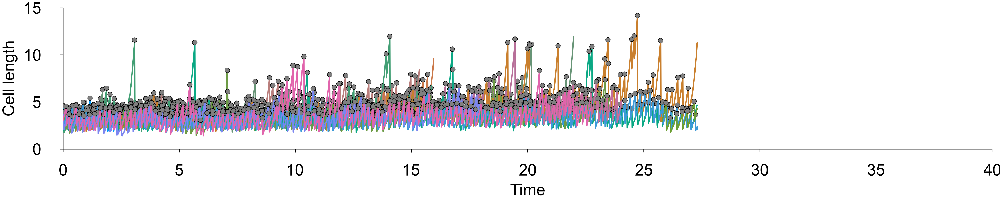

In [7]:
p_traj_obs = plot(; size=(1500,300), xlim=(0,40), ylim=(0,15), xtick=collect(0:5:40), ytick=collect(0:5:15), bottommargin=12Plots.mm,  leftmargin=9Plots.mm, xlabel="Time", ylabel="Cell length")
linecolor_ = palette(:default, length(Lobs_) )
for i in eachindex(Lobs_)
    plot!(p_traj_obs, tobs_[i], Lobs_[i], lc=linecolor_[i])
    scatter!(p_traj_obs, tobs_[i][isdiv_[i]], Lobs_[i][isdiv_[i]], markercolor=:gray)
end
p_traj_obs

### xy02

In [8]:
using DelimitedFiles
using Plots
# INSERT YOUR OWN DATA DIRECTORY AND FILENAME HERE
# E. coli MG1655 (CGSC 6300)/20090131/xy01c1/ch1_cell0.dat
data_dir = "/Users/shijiezhang/Dropbox (MIT)/stochastic_learning/complete data Curr Biol 20, 1099-1103 (2010)/E. coli MG1655 (CGSC 6300)/20090129/xy02/"
filename_all = readdir(data_dir);
DT = 0.01;
DL = 0.05;

In [9]:
select_filename = Vector{String}(undef, 9)
select_filename[1] = "ch0_cell0.dat"
select_filename[2] = "ch1_cell0.dat"
select_filename[3] = "ch2_cell0.dat"
select_filename[4] = "ch3_cell0.dat"
select_filename[5] = "ch4_cell0.dat"
select_filename[6] = "ch5_cell0.dat"
select_filename[7] = "ch6_cell0.dat"
select_filename[8] = "ch7_cell0.dat"
select_filename[9] = "ch8_cell0.dat"



"ch8_cell0.dat"

In [10]:

select_time_all = Vector{Vector{Tuple{Float64, Float64}}}(undef, length(select_filename))
select_time_all[1] = [(0, 20.46)]
select_time_all[2] = [(0, 27.31)] 
select_time_all[3] = [(0, 27.31)] 
select_time_all[4] = [(0., 27.31)]
select_time_all[5] = [(0, 27.31)] 
select_time_all[6] = [(0, 20.39)] 
select_time_all[7] = [(0, 27.31)]
select_time_all[8] = [(0, 27.31)] 
select_time_all[9] = [(10.66, 27.31)] 

# annotate
Lobs_ = []
tobs_ = []



Any[]

In [11]:
for idx in eachindex(select_filename)
    tab = readdlm(data_dir * select_filename[idx]);
    varnames = convert(Vector{String}, tab[1,:]);
    tobs = tab[2:end,findfirst(varnames .== "time")] * DT;
    Lobs = tab[2:end,findfirst(varnames .== "length")] * DL;
    Lobs_idx, tobs_idx = filter_exp_traj(Lobs, tobs; select_time = select_time_all[idx]);
    Lobs_ = vcat(Lobs_, Lobs_idx)
    tobs_ = vcat(tobs_, tobs_idx)
end
Lobs_ = convert.(Vector{Float64}, Lobs_);
tobs_ = convert.(Vector{Float64}, tobs_);

In [12]:
isdiv_, dtobs_ = annotate_exp_traj(Lobs_, tobs_);
sum(vcat(isdiv_...))

1031

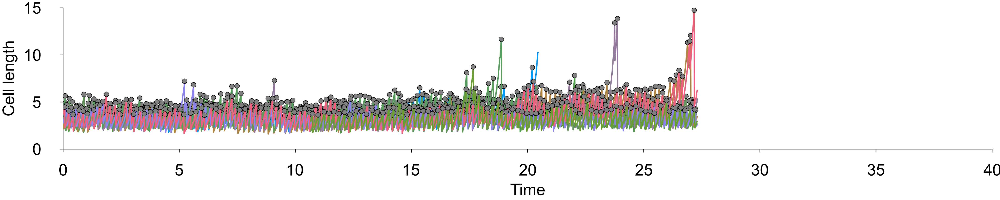

In [13]:
p_traj_obs = plot(; size=(1500,300), xlim=(0,40), ylim=(0,15), xtick=collect(0:5:40), ytick=collect(0:5:15), bottommargin=12Plots.mm,  leftmargin=9Plots.mm, xlabel="Time", ylabel="Cell length")
linecolor_ = palette(:default, length(Lobs_) )
for i in eachindex(Lobs_)
    plot!(p_traj_obs, tobs_[i], Lobs_[i], lc=linecolor_[i])
    scatter!(p_traj_obs, tobs_[i][isdiv_[i]], Lobs_[i][isdiv_[i]], markercolor=:gray)
end
p_traj_obs

### xy03

In [14]:
using DelimitedFiles
using Plots
# INSERT YOUR OWN DATA DIRECTORY AND FILENAME HERE
# E. coli MG1655 (CGSC 6300)/20090131/xy01c1/ch1_cell0.dat
data_dir = "/Users/shijiezhang/Dropbox (MIT)/stochastic_learning/complete data Curr Biol 20, 1099-1103 (2010)/E. coli MG1655 (CGSC 6300)/20090129/xy03/"
filename_all = readdir(data_dir);
DT = 0.01;
DL = 0.05;

In [15]:
select_filename = Vector{String}(undef, 11)
select_filename[1] = "ch0_cell0.dat"
select_filename[2] = "ch1_cell0.dat"
select_filename[3] = "ch2_cell0.dat"
select_filename[4] = "ch3_cell0.dat"
select_filename[5] = "ch4_cell0.dat"
select_filename[6] = "ch5_cell0.dat"
select_filename[7] = "ch6_cell0.dat"
select_filename[8] = "ch7_cell0.dat"
select_filename[9] = "ch8_cell0.dat"
select_filename[10] = "ch9_cell0.dat"
select_filename[11] = "ch10_cell0.dat"


"ch10_cell0.dat"

In [16]:
select_time_all = Vector{Vector{Tuple{Float64, Float64}}}(undef, length(select_filename))
select_time_all[1] = [(0, 27.31)]
select_time_all[2] = [(0.0, 17.76)] 
select_time_all[3] = [(0, 5.05)] 
select_time_all[4] = [(0., 16.39), (17.28, 20.44)]
select_time_all[5] = [(0, 19.20)] 
select_time_all[6] = [(0, 25.21)] 
select_time_all[7] = [(0, 13.38), (17.38, 27.31)]
select_time_all[8] = [(0, 27.31)] 
select_time_all[9] = [(0, 27.31)] 
select_time_all[10] = [(0, 27.31)] 
select_time_all[11] = [(8.17, 14.08)] 

1-element Vector{Tuple{Float64, Float64}}:
 (8.17, 14.08)

In [17]:
# annotate
Lobs_ = []
tobs_ = []
for idx in eachindex(select_filename)
    tab = readdlm(data_dir * select_filename[idx]);
    varnames = convert(Vector{String}, tab[1,:]);
    tobs = tab[2:end,findfirst(varnames .== "time")] * DT;
    Lobs = tab[2:end,findfirst(varnames .== "length")] * DL;
    Lobs_idx, tobs_idx = filter_exp_traj(Lobs, tobs; select_time = select_time_all[idx] );
    Lobs_ = vcat(Lobs_, Lobs_idx)
    tobs_ = vcat(tobs_, tobs_idx)
end
Lobs_ = convert.(Vector{Float64}, Lobs_);
tobs_ = convert.(Vector{Float64}, tobs_);

In [18]:
isdiv_, dtobs_ = annotate_exp_traj(Lobs_, tobs_);

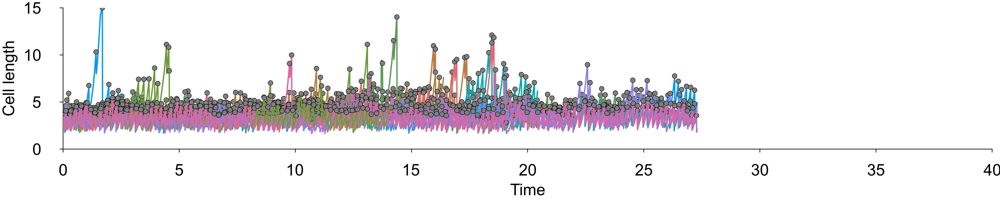

In [19]:
p_traj_obs = plot(; size=(1500,300), xlim=(0,40), ylim=(0,15), xtick=collect(0:5:40), ytick=collect(0:5:15), bottommargin=12Plots.mm,  leftmargin=9Plots.mm, xlabel="Time", ylabel="Cell length")
linecolor_ = palette(:default, length(Lobs_) )
for i in eachindex(Lobs_)
    plot!(p_traj_obs, tobs_[i], Lobs_[i], lc=linecolor_[i])
    scatter!(p_traj_obs, tobs_[i][isdiv_[i]], Lobs_[i][isdiv_[i]], markercolor=:gray)
end
p_traj_obs

### xy04

In [20]:
using DelimitedFiles
using Plots
# INSERT YOUR OWN DATA DIRECTORY AND FILENAME HERE
# E. coli MG1655 (CGSC 6300)/20090131/xy01c1/ch1_cell0.dat
data_dir = "/Users/shijiezhang/Dropbox (MIT)/stochastic_learning/complete data Curr Biol 20, 1099-1103 (2010)/E. coli MG1655 (CGSC 6300)/20090129/xy04/"
filename_all = readdir(data_dir);
DT = 0.01;
DL = 0.05;

In [21]:
select_filename = Vector{String}(undef, 10)
select_filename[1] = "ch0_cell0.dat"
select_filename[2] = "ch1_cell0.dat"
select_filename[3] = "ch2_cell0.dat"
select_filename[4] = "ch3_cell0.dat"
select_filename[5] = "ch4_cell0.dat"
select_filename[6] = "ch5_cell0.dat"
select_filename[7] = "ch6_cell0.dat"
select_filename[8] = "ch7_cell0.dat"
select_filename[9] = "ch8_cell0.dat"
select_filename[10] = "ch9_cell0.dat"
# select_filename[11] = "ch10_cell0.dat"


"ch9_cell0.dat"

In [22]:
select_time_all = Vector{Vector{Tuple{Float64, Float64}}}(undef, length(select_filename))
select_time_all[1] = [(0, 20.69)]
select_time_all[2] = [(0.0, 24.66)] 
select_time_all[3] = [(0, 20.96)] 
select_time_all[4] = [(0., 16.28)]
select_time_all[5] = [(0, 27.31)] 
select_time_all[6] = [(0, 16.30)] 
select_time_all[7] = [(0, 20.22)]
select_time_all[8] = [(0, 17.14), (17.96, 27.31)] 
select_time_all[9] = [(0, 11.65)] 
select_time_all[10] = [(0, 24.52)] 
# select_time_all[11] = [] 

1-element Vector{Tuple{Int64, Float64}}:
 (0, 24.52)

In [23]:
# annotate
Lobs_ = []
tobs_ = []
for idx in eachindex(select_filename)
    tab = readdlm(data_dir * select_filename[idx]);
    varnames = convert(Vector{String}, tab[1,:]);
    tobs = tab[2:end,findfirst(varnames .== "time")] * DT;
    Lobs = tab[2:end,findfirst(varnames .== "length")] * DL;
    Lobs_idx, tobs_idx = filter_exp_traj(Lobs, tobs; select_time = select_time_all[idx] );
    Lobs_ = vcat(Lobs_, Lobs_idx)
    tobs_ = vcat(tobs_, tobs_idx)
end
Lobs_ = convert.(Vector{Float64}, Lobs_);
tobs_ = convert.(Vector{Float64}, tobs_);
isdiv_, dtobs_ = annotate_exp_traj(Lobs_, tobs_);

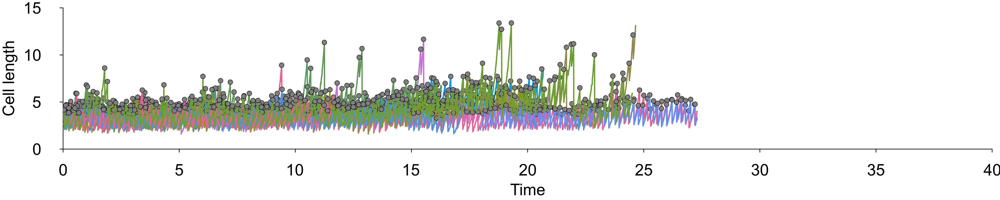

In [24]:
p_traj_obs = plot(; size=(1500,300), xlim=(0,40), ylim=(0,15), xtick=collect(0:5:40), ytick=collect(0:5:15), bottommargin=12Plots.mm,  leftmargin=9Plots.mm, xlabel="Time", ylabel="Cell length")
linecolor_ = palette(:default, length(Lobs_) )
for i in eachindex(Lobs_)
    plot!(p_traj_obs, tobs_[i], Lobs_[i], lc=linecolor_[i])
    scatter!(p_traj_obs, tobs_[i][isdiv_[i]], Lobs_[i][isdiv_[i]], markercolor=:gray)
end
p_traj_obs

### xy05

In [25]:
using DelimitedFiles
using Plots
# INSERT YOUR OWN DATA DIRECTORY AND FILENAME HERE
# E. coli MG1655 (CGSC 6300)/20090131/xy01c1/ch1_cell0.dat
data_dir = "/Users/shijiezhang/Dropbox (MIT)/stochastic_learning/complete data Curr Biol 20, 1099-1103 (2010)/E. coli MG1655 (CGSC 6300)/20090129/xy05/"
filename_all = readdir(data_dir);
DT = 0.01;
DL = 0.05;

In [26]:
select_filename = Vector{String}(undef, 13)
select_filename[1] = "ch0_cell0.dat"
select_filename[2] = "ch1_cell0.dat"
select_filename[3] = "ch2_cell0.dat"
select_filename[4] = "ch3_cell0.dat"
select_filename[5] = "ch4_cell0.dat"
select_filename[6] = "ch5_cell0.dat"
select_filename[7] = "ch6_cell0.dat"
select_filename[8] = "ch7_cell0.dat"
select_filename[9] = "ch8_cell0.dat"
select_filename[10] = "ch9_cell0.dat"
select_filename[11] = "ch10_cell0.dat"
select_filename[12] = "ch11_cell0.dat"
select_filename[13] = "ch12_cell0.dat"


"ch12_cell0.dat"

In [27]:
select_time_all = Vector{Vector{Tuple{Float64, Float64}}}(undef, length(select_filename))
select_time_all[1] = [(0, 27.31)]
select_time_all[2] = [(0.0, 14.32)] 
select_time_all[3] = [(0, 14.12)] 
select_time_all[4] = [(0., 19.20), (20.06, 24.38)]
select_time_all[5] = [(0, 16.83)] 
select_time_all[6] = [(3.39, 15.45)] 
select_time_all[7] = [(0, 24.18)]
select_time_all[8] = [(0, 24.86)] 
select_time_all[9] = [(0, 27.31)] 
select_time_all[10] = [(0, 16.58)] 
select_time_all[11] = [(0, 27.31)] 
select_time_all[12] = [(0, 13.03)] 
select_time_all[13] = [(0, 27.31)] 

1-element Vector{Tuple{Int64, Float64}}:
 (0, 27.31)

In [28]:
# annotate
Lobs_ = []
tobs_ = []
for idx in eachindex(select_filename)
    tab = readdlm(data_dir * select_filename[idx]);
    varnames = convert(Vector{String}, tab[1,:]);
    tobs = tab[2:end,findfirst(varnames .== "time")] * DT;
    Lobs = tab[2:end,findfirst(varnames .== "length")] * DL;
    Lobs_idx, tobs_idx = filter_exp_traj(Lobs, tobs; select_time = select_time_all[idx] );
    Lobs_ = vcat(Lobs_, Lobs_idx)
    tobs_ = vcat(tobs_, tobs_idx)
end
Lobs_ = convert.(Vector{Float64}, Lobs_);
tobs_ = convert.(Vector{Float64}, tobs_);
isdiv_, dtobs_ = annotate_exp_traj(Lobs_, tobs_);

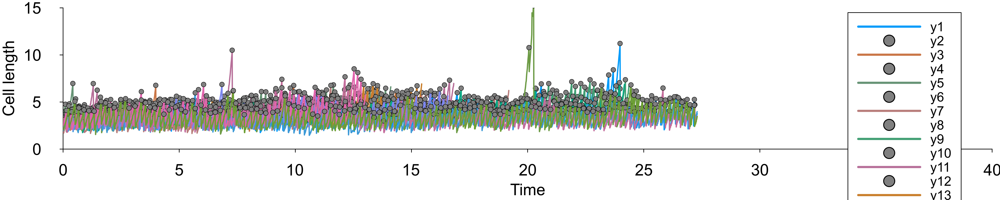

In [29]:
p_traj_obs = plot(; size=(1500,300), xlim=(0,40), ylim=(0,15), xtick=collect(0:5:40), ytick=collect(0:5:15), bottommargin=12Plots.mm,  leftmargin=9Plots.mm, xlabel="Time", ylabel="Cell length")
linecolor_ = palette(:default, length(Lobs_) )
for i in eachindex(Lobs_)
    plot!(p_traj_obs, tobs_[i], Lobs_[i], lc=linecolor_[i], legend =:true)
    scatter!(p_traj_obs, tobs_[i][isdiv_[i]], Lobs_[i][isdiv_[i]], markercolor=:gray)
end
p_traj_obs

### xy06

In [30]:
using DelimitedFiles
using Plots
# INSERT YOUR OWN DATA DIRECTORY AND FILENAME HERE
# E. coli MG1655 (CGSC 6300)/20090131/xy01c1/ch1_cell0.dat
data_dir = "/Users/shijiezhang/Dropbox (MIT)/stochastic_learning/complete data Curr Biol 20, 1099-1103 (2010)/E. coli MG1655 (CGSC 6300)/20090129/xy06/"
filename_all = readdir(data_dir);
DT = 0.01;
DL = 0.05;

In [31]:
select_filename = Vector{String}(undef, 10)
select_filename[1] = "ch0_cell0.dat"
select_filename[2] = "ch1_cell0.dat"
select_filename[3] = "ch2_cell0.dat"
select_filename[4] = "ch3_cell0.dat"
select_filename[5] = "ch4_cell0.dat"
select_filename[6] = "ch5_cell0.dat"
select_filename[7] = "ch6_cell0.dat"
select_filename[8] = "ch7_cell0.dat"
select_filename[9] = "ch8_cell0.dat"
select_filename[10] = "ch9_cell0.dat"



"ch9_cell0.dat"

In [32]:
select_time_all = Vector{Vector{Tuple{Float64, Float64}}}(undef, length(select_filename))
select_time_all[1] = [(0, 27.31)]
select_time_all[2] = [(0, 27.31)] 
select_time_all[3] = [(0, 4.46)] 
select_time_all[4] = [(0., 20.58)]
select_time_all[5] = [(0, 27.31)] 
select_time_all[6] = [(0, 27.31)] 
select_time_all[7] = [(0, 27.31)]
select_time_all[8] = [(0, 27.31)] 
select_time_all[9] = [(1.31, 27.31)] 
select_time_all[10] = [(11.24, 27.31)] 


1-element Vector{Tuple{Float64, Float64}}:
 (11.24, 27.31)

In [33]:
# annotate
Lobs_ = []
tobs_ = []
for idx in eachindex(select_filename)
    tab = readdlm(data_dir * select_filename[idx]);
    varnames = convert(Vector{String}, tab[1,:]);
    tobs = tab[2:end,findfirst(varnames .== "time")] * DT;
    Lobs = tab[2:end,findfirst(varnames .== "length")] * DL;
    Lobs_idx, tobs_idx = filter_exp_traj(Lobs, tobs; select_time = select_time_all[idx] );
    Lobs_ = vcat(Lobs_, Lobs_idx)
    tobs_ = vcat(tobs_, tobs_idx)
end
Lobs_ = convert.(Vector{Float64}, Lobs_);
tobs_ = convert.(Vector{Float64}, tobs_);
isdiv_, dtobs_ = annotate_exp_traj(Lobs_, tobs_);

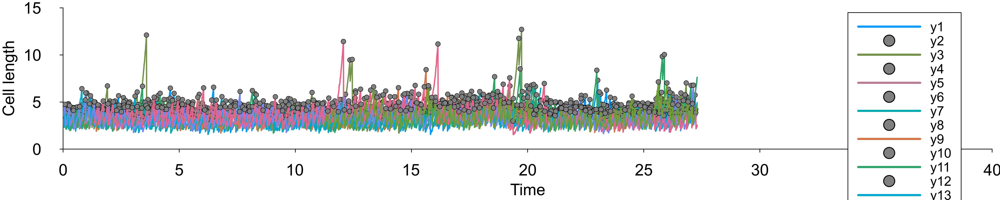

In [34]:
p_traj_obs = plot(; size=(1500,300), xlim=(0,40), ylim=(0,15), xtick=collect(0:5:40), ytick=collect(0:5:15), bottommargin=12Plots.mm,  leftmargin=9Plots.mm, xlabel="Time", ylabel="Cell length")
linecolor_ = palette(:default, length(Lobs_) )
for i in eachindex(Lobs_)
    plot!(p_traj_obs, tobs_[i], Lobs_[i], lc=linecolor_[i], legend =:true)
    scatter!(p_traj_obs, tobs_[i][isdiv_[i]], Lobs_[i][isdiv_[i]], markercolor=:gray)
end
p_traj_obs

### xy07

In [35]:
using DelimitedFiles
using Plots
# INSERT YOUR OWN DATA DIRECTORY AND FILENAME HERE
# E. coli MG1655 (CGSC 6300)/20090131/xy01c1/ch1_cell0.dat
data_dir = "/Users/shijiezhang/Dropbox (MIT)/stochastic_learning/complete data Curr Biol 20, 1099-1103 (2010)/E. coli MG1655 (CGSC 6300)/20090129/xy07/"
filename_all = readdir(data_dir);
DT = 0.01;
DL = 0.05;

In [36]:
select_filename = Vector{String}(undef, 11)
select_filename[1] = "ch0_cell0.dat"
select_filename[2] = "ch1_cell0.dat"
select_filename[3] = "ch2_cell0.dat"
select_filename[4] = "ch3_cell0.dat"
select_filename[5] = "ch4_cell0.dat"
select_filename[6] = "ch5_cell0.dat"
select_filename[7] = "ch6_cell0.dat"
select_filename[8] = "ch7_cell0.dat"
select_filename[9] = "ch8_cell0.dat"
select_filename[10] = "ch10_cell0.dat"
select_filename[11] = "ch11_cell0.dat"


"ch11_cell0.dat"

In [37]:
select_time_all = Vector{Vector{Tuple{Float64, Float64}}}(undef, length(select_filename))
select_time_all[1] = [(0, 27.31)]
select_time_all[2] = [(0, 2.41), (3.19, 16.21), (17.28, 27.31)] 
select_time_all[3] = [(0, 26.09)] 
select_time_all[4] = [(0., 23.46)]
select_time_all[5] = [(0, 2.14)] 
select_time_all[6] = [(0, 16.36)] 
select_time_all[7] = [(0, 24.91)]
select_time_all[8] = [(0, 26.97)] 
select_time_all[9] = [(1.04, 17.89)] 
select_time_all[10] = [(21.36, 27.31)] 
select_time_all[11] = [(22.41, 27.31)] 


1-element Vector{Tuple{Float64, Float64}}:
 (22.41, 27.31)

In [38]:
# annotate
Lobs_ = []
tobs_ = []
for idx in eachindex(select_filename)
    tab = readdlm(data_dir * select_filename[idx]);
    varnames = convert(Vector{String}, tab[1,:]);
    tobs = tab[2:end,findfirst(varnames .== "time")] * DT;
    Lobs = tab[2:end,findfirst(varnames .== "length")] * DL;
    Lobs_idx, tobs_idx = filter_exp_traj(Lobs, tobs; select_time = select_time_all[idx] );
    Lobs_ = vcat(Lobs_, Lobs_idx)
    tobs_ = vcat(tobs_, tobs_idx)
end
Lobs_ = convert.(Vector{Float64}, Lobs_);
tobs_ = convert.(Vector{Float64}, tobs_);
isdiv_, dtobs_ = annotate_exp_traj(Lobs_, tobs_);

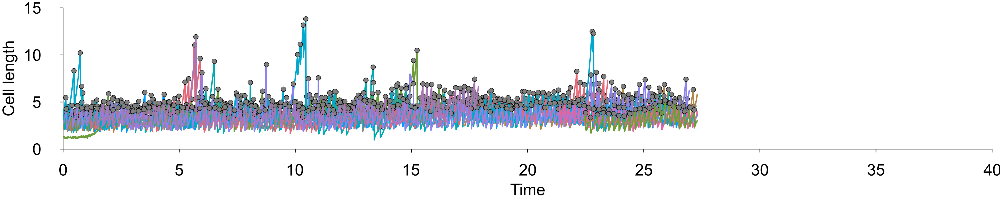

In [39]:
p_traj_obs = plot(; size=(1500,300), xlim=(0,40), ylim=(0,15), xtick=collect(0:5:40), ytick=collect(0:5:15), bottommargin=12Plots.mm,  leftmargin=9Plots.mm, xlabel="Time", ylabel="Cell length")
linecolor_ = palette(:default, length(Lobs_) )
for i in eachindex(Lobs_)
    plot!(p_traj_obs, tobs_[i], Lobs_[i], lc=linecolor_[i])
    scatter!(p_traj_obs, tobs_[i][isdiv_[i]], Lobs_[i][isdiv_[i]], markercolor=:gray)
end
p_traj_obs

### xy08

In [40]:
using DelimitedFiles
using Plots
# INSERT YOUR OWN DATA DIRECTORY AND FILENAME HERE
# E. coli MG1655 (CGSC 6300)/20090131/xy01c1/ch1_cell0.dat
data_dir = "/Users/shijiezhang/Dropbox (MIT)/stochastic_learning/complete data Curr Biol 20, 1099-1103 (2010)/E. coli MG1655 (CGSC 6300)/20090129/xy08/"
filename_all = readdir(data_dir);
DT = 0.01;
DL = 0.05;

In [41]:
select_filename = Vector{String}(undef, 10)
select_filename[1] = "ch0_cell0.dat"
select_filename[2] = "ch1_cell0.dat"
select_filename[3] = "ch3_cell0.dat"
select_filename[4] = "ch4_cell0.dat"
select_filename[5] = "ch5_cell0.dat"
select_filename[6] = "ch6_cell0.dat"
select_filename[7] = "ch7_cell0.dat"
select_filename[8] = "ch8_cell0.dat"
select_filename[9] = "ch9_cell0.dat"
select_filename[10] = "ch10_cell0.dat"



"ch10_cell0.dat"

In [42]:
select_time_all = Vector{Vector{Tuple{Float64, Float64}}}(undef, length(select_filename))
select_time_all[1] = [(0, 23.34)]
select_time_all[2] = [(0, 18.77)] 
select_time_all[3] = [(0, 8.82)] 
select_time_all[4] = [(0., 7.98)]
select_time_all[5] = [(0, 27.31)] 
select_time_all[6] = [(0, 16.26)] 
select_time_all[7] = [(0, 27.31)]
select_time_all[8] = [(0, 27.31)] 
select_time_all[9] = [(0, 27.31)] 
select_time_all[10] = [(0, 27.31)] 



1-element Vector{Tuple{Int64, Float64}}:
 (0, 27.31)

In [43]:
# annotate
Lobs_ = []
tobs_ = []
for idx in eachindex(select_filename)
    tab = readdlm(data_dir * select_filename[idx]);
    varnames = convert(Vector{String}, tab[1,:]);
    tobs = tab[2:end,findfirst(varnames .== "time")] * DT;
    Lobs = tab[2:end,findfirst(varnames .== "length")] * DL;
    Lobs_idx, tobs_idx = filter_exp_traj(Lobs, tobs; select_time = select_time_all[idx] );
    Lobs_ = vcat(Lobs_, Lobs_idx)
    tobs_ = vcat(tobs_, tobs_idx)
end
Lobs_ = convert.(Vector{Float64}, Lobs_);
tobs_ = convert.(Vector{Float64}, tobs_);
isdiv_, dtobs_ = annotate_exp_traj(Lobs_, tobs_);

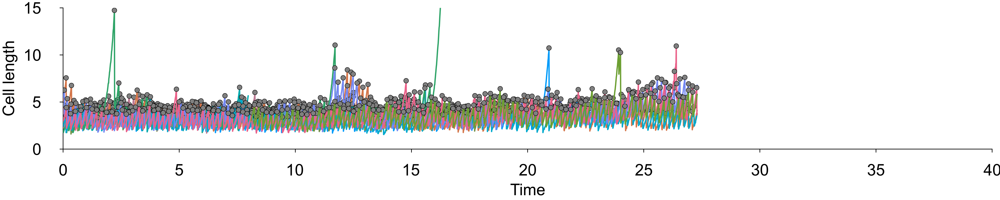

In [44]:
p_traj_obs = plot(; size=(1500,300), xlim=(0,40), ylim=(0,15), xtick=collect(0:5:40), ytick=collect(0:5:15), bottommargin=12Plots.mm,  leftmargin=9Plots.mm, xlabel="Time", ylabel="Cell length")
linecolor_ = palette(:default, length(Lobs_) )
for i in eachindex(Lobs_)
    plot!(p_traj_obs, tobs_[i], Lobs_[i], lc=linecolor_[i])
    scatter!(p_traj_obs, tobs_[i][isdiv_[i]], Lobs_[i][isdiv_[i]], markercolor=:gray)
end
p_traj_obs

### xy09

In [45]:
using DelimitedFiles
using Plots
# INSERT YOUR OWN DATA DIRECTORY AND FILENAME HERE
# E. coli MG1655 (CGSC 6300)/20090131/xy01c1/ch1_cell0.dat
data_dir = "/Users/shijiezhang/Dropbox (MIT)/stochastic_learning/complete data Curr Biol 20, 1099-1103 (2010)/E. coli MG1655 (CGSC 6300)/20090129/xy09/"
filename_all = readdir(data_dir);
DT = 0.01;
DL = 0.05;

In [46]:
select_filename = Vector{String}(undef, 12)
select_filename[1] = "ch0_cell0.dat"
select_filename[2] = "ch1_cell0.dat"
select_filename[3] = "ch2_cell0.dat"
select_filename[4] = "ch3_cell0.dat"
select_filename[5] = "ch4_cell0.dat"
select_filename[6] = "ch5_cell0.dat"
select_filename[7] = "ch6_cell0.dat"
select_filename[8] = "ch7_cell0.dat"
select_filename[9] = "ch8_cell0.dat"
select_filename[10] = "ch9_cell0.dat"
select_filename[11] = "ch10_cell0.dat"
select_filename[12] = "ch11_cell0.dat"


"ch11_cell0.dat"

In [47]:
select_time_all = Vector{Vector{Tuple{Float64, Float64}}}(undef, length(select_filename))
select_time_all[1] = [(0, 15.66)]
select_time_all[2] = [(0, 12.58)] 
select_time_all[3] = [(0, 26.61)] 
select_time_all[4] = [(0., 5.80)]
select_time_all[5] = [(0, 27.31)] 
select_time_all[6] = [(0, 14.05)] 
select_time_all[7] = [(0, 27.31)]
select_time_all[8] = [(0, 20.02)] 
select_time_all[9] = [(0, 18.38)] 
select_time_all[10] = [(0, 6.58)] 
select_time_all[11] = [(17.89, 27.31)] 
select_time_all[12] = [(20.25, 27.31)] 



1-element Vector{Tuple{Float64, Float64}}:
 (20.25, 27.31)

In [48]:
# annotate
Lobs_ = []
tobs_ = []
for idx in eachindex(select_filename)
    tab = readdlm(data_dir * select_filename[idx]);
    varnames = convert(Vector{String}, tab[1,:]);
    tobs = tab[2:end,findfirst(varnames .== "time")] * DT;
    Lobs = tab[2:end,findfirst(varnames .== "length")] * DL;
    Lobs_idx, tobs_idx = filter_exp_traj(Lobs, tobs; select_time = select_time_all[idx] );
    Lobs_ = vcat(Lobs_, Lobs_idx)
    tobs_ = vcat(tobs_, tobs_idx)
end
Lobs_ = convert.(Vector{Float64}, Lobs_);
tobs_ = convert.(Vector{Float64}, tobs_);
isdiv_, dtobs_ = annotate_exp_traj(Lobs_, tobs_);

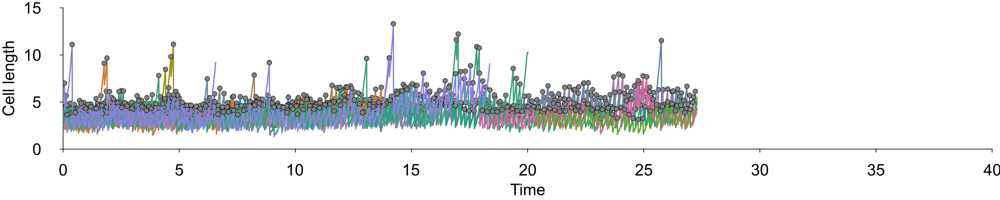

In [49]:
p_traj_obs = plot(; size=(1500,300), xlim=(0,40), ylim=(0,15), xtick=collect(0:5:40), ytick=collect(0:5:15), bottommargin=12Plots.mm,  leftmargin=9Plots.mm, xlabel="Time", ylabel="Cell length")
linecolor_ = palette(:default, length(Lobs_) )
for i in eachindex(Lobs_)
    plot!(p_traj_obs, tobs_[i], Lobs_[i], lc=linecolor_[i])
    scatter!(p_traj_obs, tobs_[i][isdiv_[i]], Lobs_[i][isdiv_[i]], markercolor=:gray)
end
p_traj_obs

### xy10

In [50]:
using DelimitedFiles
using Plots
# INSERT YOUR OWN DATA DIRECTORY AND FILENAME HERE
# E. coli MG1655 (CGSC 6300)/20090131/xy01c1/ch1_cell0.dat
data_dir = "/Users/shijiezhang/Dropbox (MIT)/stochastic_learning/complete data Curr Biol 20, 1099-1103 (2010)/E. coli MG1655 (CGSC 6300)/20090129/xy10/"
filename_all = readdir(data_dir);
DT = 0.01;
DL = 0.05;

In [51]:
select_filename = Vector{String}(undef, 14)
select_filename[1] = "ch0_cell0.dat"
select_filename[2] = "ch1_cell0.dat"
select_filename[3] = "ch2_cell0.dat"
select_filename[4] = "ch3_cell0.dat"
select_filename[5] = "ch4_cell0.dat"
select_filename[6] = "ch5_cell0.dat"
select_filename[7] = "ch6_cell0.dat"
select_filename[8] = "ch7_cell0.dat"
select_filename[9] = "ch8_cell0.dat"
select_filename[10] = "ch9_cell0.dat"
select_filename[11] = "ch10_cell0.dat"
select_filename[12] = "ch11_cell0.dat"
select_filename[13] = "ch12_cell0.dat"
select_filename[14] = "ch13_cell0.dat"


"ch13_cell0.dat"

In [52]:
select_time_all = Vector{Vector{Tuple{Float64, Float64}}}(undef, length(select_filename))
select_time_all[1] = [(0, 15.66)]
select_time_all[2] = [(0, 12.58)] 
select_time_all[3] = [(0, 7.64)] 
select_time_all[4] = [(0., 23.50)]
select_time_all[5] = [(0, 8.71), (9.08, 12.02), (12.51, 14.89)] 
select_time_all[6] = [(0, 15.18), (15.77, 18.26)] 
select_time_all[7] = [(0, 27.31)]
select_time_all[8] = [(0, 227.31)] 
select_time_all[9] = [(0, 27.31)] 
select_time_all[10] = [(0, 16.88)] 
select_time_all[11] = [(0, 27.31)] 
select_time_all[12] = [(7.03, 27.31)] 
select_time_all[13] = [(13.83, 27.31)] 
select_time_all[14] = [(21.10, 27.31)] 



1-element Vector{Tuple{Float64, Float64}}:
 (21.1, 27.31)

In [53]:
# annotate
Lobs_ = []
tobs_ = []
for idx in eachindex(select_filename)
    tab = readdlm(data_dir * select_filename[idx]);
    varnames = convert(Vector{String}, tab[1,:]);
    tobs = tab[2:end,findfirst(varnames .== "time")] * DT;
    Lobs = tab[2:end,findfirst(varnames .== "length")] * DL;
    Lobs_idx, tobs_idx = filter_exp_traj(Lobs, tobs; select_time = select_time_all[idx] );
    Lobs_ = vcat(Lobs_, Lobs_idx)
    tobs_ = vcat(tobs_, tobs_idx)
end
Lobs_ = convert.(Vector{Float64}, Lobs_);
tobs_ = convert.(Vector{Float64}, tobs_);
isdiv_, dtobs_ = annotate_exp_traj(Lobs_, tobs_);

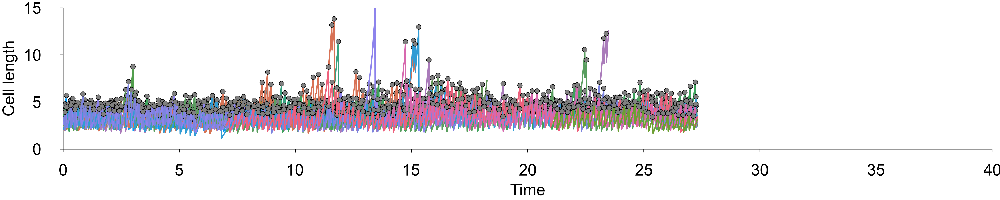

In [54]:
p_traj_obs = plot(; size=(1500,300), xlim=(0,40), ylim=(0,15), xtick=collect(0:5:40), ytick=collect(0:5:15), bottommargin=12Plots.mm,  leftmargin=9Plots.mm, xlabel="Time", ylabel="Cell length")
linecolor_ = palette(:default, length(Lobs_) )
for i in eachindex(Lobs_)
    plot!(p_traj_obs, tobs_[i], Lobs_[i], lc=linecolor_[i])
    scatter!(p_traj_obs, tobs_[i][isdiv_[i]], Lobs_[i][isdiv_[i]], markercolor=:gray)
end
p_traj_obs

### xy11

In [55]:
using DelimitedFiles
using Plots
# INSERT YOUR OWN DATA DIRECTORY AND FILENAME HERE
# E. coli MG1655 (CGSC 6300)/20090131/xy01c1/ch1_cell0.dat
data_dir = "/Users/shijiezhang/Dropbox (MIT)/stochastic_learning/complete data Curr Biol 20, 1099-1103 (2010)/E. coli MG1655 (CGSC 6300)/20090129/xy11/"
filename_all = readdir(data_dir);
DT = 0.01;
DL = 0.05;

In [56]:
select_filename = Vector{String}(undef, 11)
select_filename[1] = "ch0_cell0.dat"
select_filename[2] = "ch1_cell0.dat"
select_filename[3] = "ch2_cell0.dat"
select_filename[4] = "ch3_cell0.dat"
select_filename[5] = "ch4_cell0.dat"
select_filename[6] = "ch5_cell0.dat"
select_filename[7] = "ch6_cell0.dat"
select_filename[8] = "ch7_cell0.dat"
select_filename[9] = "ch8_cell0.dat"
select_filename[10] = "ch9_cell0.dat"
select_filename[11] = "ch10_cell0.dat"


"ch10_cell0.dat"

In [57]:
select_time_all = Vector{Vector{Tuple{Float64, Float64}}}(undef, length(select_filename))
select_time_all[1] = [(0.90, 3.10)]
select_time_all[2] = [(0.0, 16.46)] 
select_time_all[3] = [(0, 4.90)] 
select_time_all[4] = [(0., 26.65)]
select_time_all[5] = [(0, 27.31)] 
select_time_all[6] = [(0, 13.91), (15.00, 18.78)] 
select_time_all[7] = [(0, 11.84), (12.33, 19.19)]
select_time_all[8] = [(0, 14.71), (16.40, 26.37)] 
select_time_all[9] = [(0, 20.76)] 
select_time_all[10] = [(0,27.31)] 
select_time_all[11] = [(0, 7.19), (8.40, 16.61)] 

2-element Vector{Tuple{Real, Float64}}:
 (0, 7.19)
 (8.4, 16.61)

In [58]:
# annotate
Lobs_ = []
tobs_ = []
for idx in eachindex(select_filename)
    tab = readdlm(data_dir * select_filename[idx]);
    varnames = convert(Vector{String}, tab[1,:]);
    tobs = tab[2:end,findfirst(varnames .== "time")] * DT;
    Lobs = tab[2:end,findfirst(varnames .== "length")] * DL;
    Lobs_idx, tobs_idx = filter_exp_traj(Lobs, tobs; select_time = select_time_all[idx] );
    Lobs_ = vcat(Lobs_, Lobs_idx)
    tobs_ = vcat(tobs_, tobs_idx)
end
Lobs_ = convert.(Vector{Float64}, Lobs_);
tobs_ = convert.(Vector{Float64}, tobs_);
isdiv_, dtobs_ = annotate_exp_traj(Lobs_, tobs_);

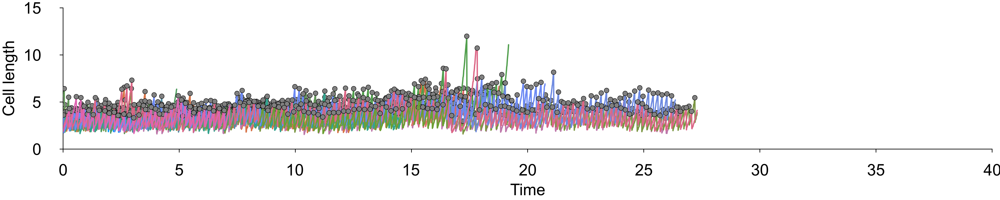

In [59]:
p_traj_obs = plot(; size=(1500,300), xlim=(0,40), ylim=(0,15), xtick=collect(0:5:40), ytick=collect(0:5:15), bottommargin=12Plots.mm,  leftmargin=9Plots.mm, xlabel="Time", ylabel="Cell length")
linecolor_ = palette(:default, length(Lobs_) )
for i in eachindex(Lobs_)
    plot!(p_traj_obs, tobs_[i], Lobs_[i], lc=linecolor_[i])
    scatter!(p_traj_obs, tobs_[i][isdiv_[i]], Lobs_[i][isdiv_[i]], markercolor=:gray)
end
p_traj_obs

### xy12

In [60]:
using DelimitedFiles
using Plots
# INSERT YOUR OWN DATA DIRECTORY AND FILENAME HERE
# E. coli MG1655 (CGSC 6300)/20090131/xy01c1/ch1_cell0.dat
data_dir = "/Users/shijiezhang/Dropbox (MIT)/stochastic_learning/complete data Curr Biol 20, 1099-1103 (2010)/E. coli MG1655 (CGSC 6300)/20090129/xy12/"
filename_all = readdir(data_dir);
DT = 0.01;
DL = 0.05;

In [61]:
select_filename = Vector{String}(undef, 5)
select_filename[1] = "ch0_cell0.dat"
select_filename[2] = "ch1_cell0.dat"
select_filename[3] = "ch2_cell0.dat"
select_filename[4] = "ch3_cell0.dat"
select_filename[5] = "ch4_cell0.dat"


"ch4_cell0.dat"

In [62]:
select_time_all = Vector{Vector{Tuple{Float64, Float64}}}(undef, length(select_filename))
select_time_all[1] = [(0, 20.96)]
select_time_all[2] = [(0, 2.31)] 
select_time_all[3] = [(0, 20.06)] 
select_time_all[4] = [(0., 25.57)]
select_time_all[5] = [(0, 11.54), (12.43, 25.71)] 


# annotate
Lobs_ = []
tobs_ = []


Any[]

In [63]:
for idx in eachindex(select_filename)
    tab = readdlm(data_dir * select_filename[idx]);
    varnames = convert(Vector{String}, tab[1,:]);
    tobs = tab[2:end,findfirst(varnames .== "time")] * DT;
    Lobs = tab[2:end,findfirst(varnames .== "length")] * DL;
    Lobs_idx, tobs_idx = filter_exp_traj(Lobs, tobs; select_time = select_time_all[idx]);
    Lobs_ = vcat(Lobs_, Lobs_idx)
    tobs_ = vcat(tobs_, tobs_idx)
end
Lobs_ = convert.(Vector{Float64}, Lobs_);
tobs_ = convert.(Vector{Float64}, tobs_);

In [64]:
isdiv_, dtobs_ = annotate_exp_traj(Lobs_, tobs_);
sum(vcat(isdiv_...))

439

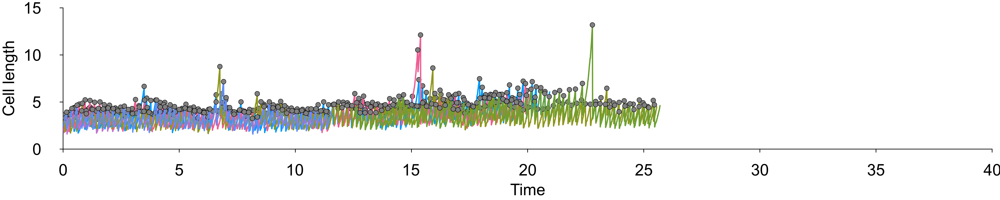

In [65]:
p_traj_obs = plot(; size=(1500,300), xlim=(0,40), ylim=(0,15), xtick=collect(0:5:40), ytick=collect(0:5:15), bottommargin=12Plots.mm,  leftmargin=9Plots.mm, xlabel="Time", ylabel="Cell length")
linecolor_ = palette(:default, length(Lobs_) )
for i in eachindex(Lobs_)
    plot!(p_traj_obs, tobs_[i], Lobs_[i], lc=linecolor_[i])
    scatter!(p_traj_obs, tobs_[i][isdiv_[i]], Lobs_[i][isdiv_[i]], markercolor=:gray)
end
p_traj_obs